<a href="https://colab.research.google.com/github/Bhuvan152/phosphene-personalization/blob/main/phosphene_personalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pulse2percept

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 8.9 MB/s  0:00:01


60 electrodes, e.g. ['A1', 'A2', 'A3', 'A4', 'A5']
Percept image shape: (177, 177)


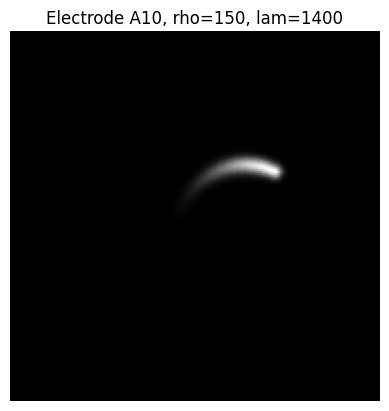

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import itertools, time
from skimage.measure import label, regionprops
from pulse2percept.implants.retina.argus import ArgusII
from pulse2percept.models.retina.beyeler2019 import AxonMapModel

XY = 0.25            # grid spacing in degrees (fine enough for thin streaks)
FIELD = (-22, 22)    # visual field wide enough that streaks don't get cut off

implant = ArgusII()
electrodes = list(implant.electrode_names)
print(len(electrodes), "electrodes, e.g.", electrodes[:5])

def make_model(rho, lam):
    m = AxonMapModel(implant, rho=rho, lam=lam, step=XY,
                     xrange=FIELD, yrange=FIELD, verbose=False)
    if hasattr(m, "build"):
        m.build()
    return m

def percept_image(model, electrode):
    return np.asarray(model.predict_percept({electrode: 1.0}).data).squeeze()

img = percept_image(make_model(150, 1400), "A10")
print("Percept image shape:", img.shape)
plt.imshow(img, cmap="gray"); plt.title("Electrode A10, rho=150, lam=1400"); plt.axis("off"); plt.show()

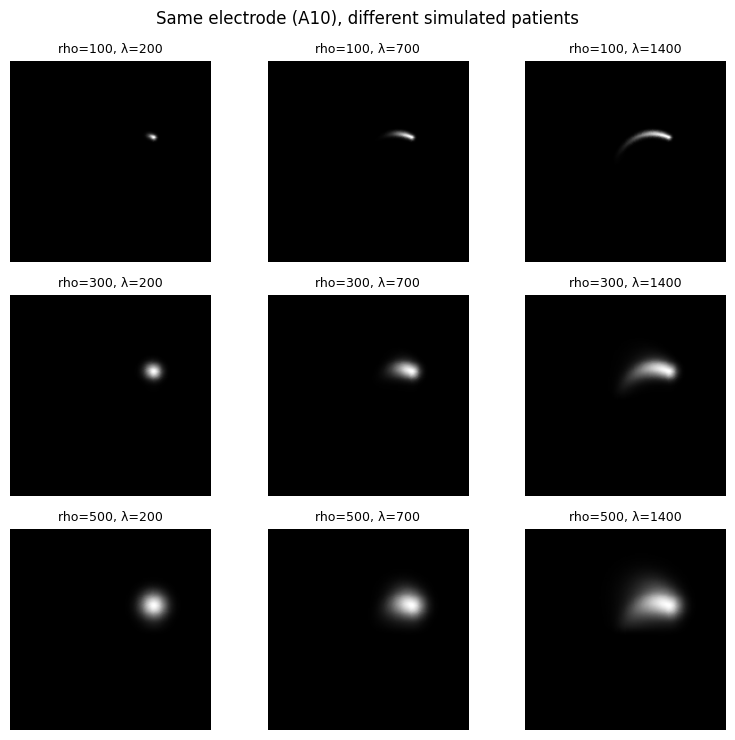

In [12]:
rhos = [100, 300, 500]
lams = [200, 700, 1400]
fig, axes = plt.subplots(3, 3, figsize=(8, 7.5))
for i, r in enumerate(rhos):
    for j, l in enumerate(lams):
        axes[i, j].imshow(percept_image(make_model(r, l), "A10"), cmap="gray")
        axes[i, j].set_title(f"rho={r}, λ={l}", fontsize=9); axes[i, j].axis("off")
plt.suptitle("Same electrode (A10), different simulated patients")
plt.tight_layout(); plt.savefig("phosphene_gallery.png", dpi=200); plt.show()

In [13]:
def shape_features(img):
    if img.max() <= 0:
        return np.array([0.0, 0.0])
    mask = img > 0.1 * img.max()
    props = max(regionprops(label(mask)), key=lambda p: p.area)
    area = props.area * XY**2
    elong = 1 - props.minor_axis_length / max(props.major_axis_length, 1e-6)
    return np.array([area, elong])

def patient_features(rho, lam):
    m = make_model(rho, lam)
    return np.array([shape_features(percept_image(m, e)) for e in electrodes])   # (60, 2)

t0 = time.time()
F_check = patient_features(150, 1400)
print(f"One patient took {time.time()-t0:.0f}s")
for e in ["A1", "A10", "F1", "F10", "C5"]:
    i = electrodes.index(e)
    print(f"{e}: area={F_check[i,0]:.1f} deg², elongation={F_check[i,1]:.2f}")

One patient took 24s
A1: area=22.4 deg², elongation=0.66
A10: area=26.4 deg², elongation=0.71
F1: area=20.1 deg², elongation=0.72
F10: area=32.4 deg², elongation=0.71
C5: area=7.6 deg², elongation=0.29


In [14]:
rho_grid = [100, 180, 260, 340, 420, 500]
lam_grid = [200, 440, 680, 920, 1160, 1400]

library = {}
t0 = time.time()
for r, l in itertools.product(rho_grid, lam_grid):
    library[(r, l)] = patient_features(r, l)
    print(f"built rho={r}, lam={l}  ({time.time()-t0:.0f}s)")

keys = list(library.keys())
LIB = np.stack([library[k] for k in keys])          # (36 patients, 60 electrodes, 2 features)
feat_std = LIB.reshape(-1, 2).std(axis=0) + 1e-9

built rho=100, lam=200  (6s)
built rho=100, lam=440  (16s)
built rho=100, lam=680  (27s)
built rho=100, lam=920  (47s)
built rho=100, lam=1160  (65s)
built rho=100, lam=1400  (82s)
built rho=180, lam=200  (87s)
built rho=180, lam=440  (94s)
built rho=180, lam=680  (104s)
built rho=180, lam=920  (117s)
built rho=180, lam=1160  (134s)
built rho=180, lam=1400  (152s)
built rho=260, lam=200  (155s)
built rho=260, lam=440  (162s)
built rho=260, lam=680  (173s)
built rho=260, lam=920  (186s)
built rho=260, lam=1160  (202s)
built rho=260, lam=1400  (221s)
built rho=340, lam=200  (224s)
built rho=340, lam=440  (231s)
built rho=340, lam=680  (242s)
built rho=340, lam=920  (255s)
built rho=340, lam=1160  (272s)
built rho=340, lam=1400  (291s)
built rho=420, lam=200  (294s)
built rho=420, lam=440  (302s)
built rho=420, lam=680  (313s)
built rho=420, lam=920  (327s)
built rho=420, lam=1160  (344s)
built rho=420, lam=1400  (364s)
built rho=500, lam=200  (368s)
built rho=500, lam=440  (375s)
built r

In [15]:
rng = np.random.default_rng(0)
test_patients = [(int(rng.uniform(100, 500)), int(rng.uniform(200, 1400))) for _ in range(10)]
test_feats = {p: patient_features(*p) for p in test_patients}
print("Test patients:", test_patients)

def estimate(F_obs, idx):
    err = (((LIB[:, idx, :] - F_obs[idx]) / feat_std) ** 2).sum(axis=(1, 2))
    return keys[int(np.argmin(err))]

ks = [1, 2, 3, 5, 8, 12, 20, 30, 60]
rho_err, lam_err = {k: [] for k in ks}, {k: [] for k in ks}
for (r, l), F in test_feats.items():
    for k in ks:
        for _ in range(50):
            idx = rng.choice(60, size=k, replace=False)
            F_noisy = F * (1 + 0.10 * rng.standard_normal(F.shape))
            r_hat, l_hat = estimate(F_noisy, idx)
            rho_err[k].append(abs(r_hat - r) / 400)
            lam_err[k].append(abs(l_hat - l) / 1200)

for k in ks:
    print(f"{k:2d} electrodes tested -> rho error {np.mean(rho_err[k]):.3f}, lam error {np.mean(lam_err[k]):.3f}")

Test patients: [(354, 523), (116, 219), (425, 1295), (342, 1075), (317, 1322), (426, 203), (442, 240), (391, 410), (445, 849), (219, 707)]
 1 electrodes tested -> rho error 0.060, lam error 0.105
 2 electrodes tested -> rho error 0.053, lam error 0.071
 3 electrodes tested -> rho error 0.050, lam error 0.059
 5 electrodes tested -> rho error 0.047, lam error 0.056
 8 electrodes tested -> rho error 0.047, lam error 0.052
12 electrodes tested -> rho error 0.046, lam error 0.052
20 electrodes tested -> rho error 0.046, lam error 0.051
30 electrodes tested -> rho error 0.045, lam error 0.052
60 electrodes tested -> rho error 0.045, lam error 0.052


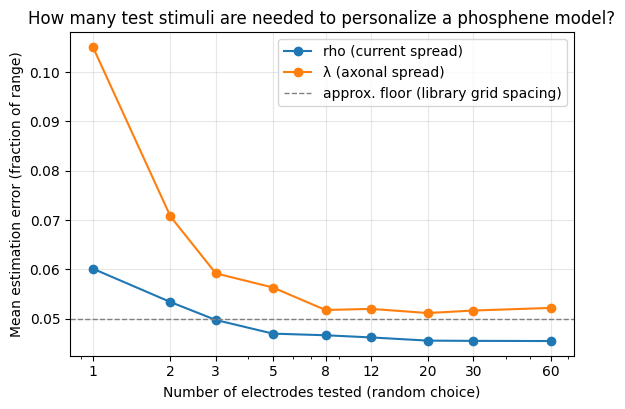

In [19]:
plt.figure(figsize=(6.5, 4.2))
plt.plot(ks, [np.mean(rho_err[k]) for k in ks], marker="o", label="rho (current spread)")
plt.plot(ks, [np.mean(lam_err[k]) for k in ks], marker="o", label="λ (axonal spread)")
plt.axhline(0.05, color="gray", linestyle="--", linewidth=1, label="approx. floor (library grid spacing)")
plt.xscale("log"); plt.xticks(ks, ks)
plt.xlabel("Number of electrodes tested (random choice)")
plt.ylabel("Mean estimation error (fraction of range)")
plt.title("How many test stimuli are needed to personalize a phosphene model?")
plt.grid(alpha=0.3); plt.legend()
plt.savefig("error_vs_electrodes.png", dpi=200, bbox_inches="tight"); plt.show()

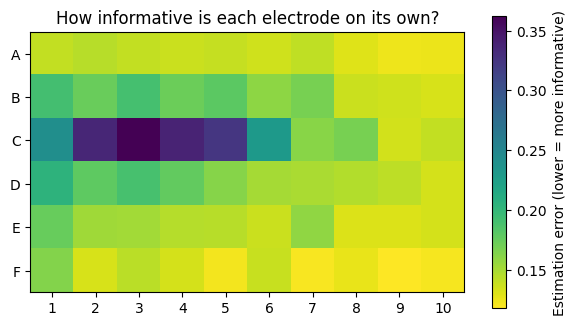

Most informative electrodes: ['F9', 'F7', 'F10', 'F5', 'A9', 'A10', 'F8', 'A8']
Least informative electrodes: ['C1', 'C5', 'C2', 'C4', 'C3']
1 electrodes -> smart choice error 0.122 vs random 0.162
2 electrodes -> smart choice error 0.114 vs random 0.129
3 electrodes -> smart choice error 0.105 vs random 0.115
5 electrodes -> smart choice error 0.101 vs random 0.106
8 electrodes -> smart choice error 0.098 vs random 0.101


In [20]:
single_err = np.zeros(60)
for i in range(60):
    errs = []
    for (r, l), F in test_feats.items():
        for _ in range(20):
            F_noisy = F * (1 + 0.10 * rng.standard_normal(F.shape))
            r_hat, l_hat = estimate(F_noisy, [i])
            errs.append(abs(r_hat - r) / 400 + abs(l_hat - l) / 1200)
    single_err[i] = np.mean(errs)

plt.figure(figsize=(7, 3.8))
plt.imshow(single_err.reshape(6, 10), cmap="viridis_r")
plt.colorbar(label="Estimation error (lower = more informative)")
plt.xticks(range(10), range(1, 11)); plt.yticks(range(6), list("ABCDEF"))
plt.title("How informative is each electrode on its own?")
plt.savefig("electrode_informativeness.png", dpi=200, bbox_inches="tight"); plt.show()

order = np.argsort(single_err)
print("Most informative electrodes:", [electrodes[i] for i in order[:8]])
print("Least informative electrodes:", [electrodes[i] for i in order[-5:]])
for k in [1, 2, 3, 5, 8]:
    smart, rand = [], []
    for (r, l), F in test_feats.items():
        for _ in range(50):
            F_noisy = F * (1 + 0.10 * rng.standard_normal(F.shape))
            for idx, store in [(order[:k], smart), (rng.choice(60, k, replace=False), rand)]:
                r_hat, l_hat = estimate(F_noisy, idx)
                store.append(abs(r_hat - r) / 400 + abs(l_hat - l) / 1200)
    print(f"{k} electrodes -> smart choice error {np.mean(smart):.3f} vs random {np.mean(rand):.3f}")

In [21]:
# New, separate patients used ONLY for ranking electrodes
rng2 = np.random.default_rng(1)
rank_patients = [(int(rng2.uniform(100, 500)), int(rng2.uniform(200, 1400))) for _ in range(10)]
rank_feats = {p: patient_features(*p) for p in rank_patients}

rank_err = np.zeros(60)
for i in range(60):
    errs = []
    for (r, l), F in rank_feats.items():
        for _ in range(20):
            F_noisy = F * (1 + 0.10 * rng2.standard_normal(F.shape))
            r_hat, l_hat = estimate(F_noisy, [i])
            errs.append(abs(r_hat - r) / 400 + abs(l_hat - l) / 1200)
    rank_err[i] = np.mean(errs)

order_fair = np.argsort(rank_err)
print("Most informative (ranked on separate patients):", [electrodes[i] for i in order_fair[:8]])

# Evaluate on the ORIGINAL test patients
for k in [1, 2, 3, 5, 8]:
    smart, rand = [], []
    for (r, l), F in test_feats.items():
        for _ in range(50):
            F_noisy = F * (1 + 0.10 * rng.standard_normal(F.shape))
            for idx, store in [(order_fair[:k], smart), (rng.choice(60, k, replace=False), rand)]:
                r_hat, l_hat = estimate(F_noisy, idx)
                store.append(abs(r_hat - r) / 400 + abs(l_hat - l) / 1200)
    print(f"{k} electrodes -> smart choice error {np.mean(smart):.3f} vs random {np.mean(rand):.3f}")

Most informative (ranked on separate patients): ['E10', 'F9', 'F8', 'D10', 'B10', 'E9', 'F7', 'F10']
1 electrodes -> smart choice error 0.131 vs random 0.170
2 electrodes -> smart choice error 0.111 vs random 0.125
3 electrodes -> smart choice error 0.105 vs random 0.116
5 electrodes -> smart choice error 0.103 vs random 0.105
8 electrodes -> smart choice error 0.099 vs random 0.100


In [22]:
from google.colab import files
for f in ["phosphene_gallery.png", "error_vs_electrodes.png", "electrode_informativeness.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>